# 04. The mission, reverse-engineered

What was the boat actually told to do? We rebuild the operator's plan from the telemetry, **one line per command**: *from this time to this time, MANUAL; at this time, switch to AUTO; …*

1. **Mode timeline:** every change of autopilot mode or arming, nothing absorbed or smoothed, plus clear speed steps inside motor-on lines
2. **Inside each leg:** speed and motor power over time, and how they relate, leg by leg
3. **The mission:** the full list of commands, saved for the forecast

The Starlink schedule (when the terminal wakes, a boat setting that runs alongside the modes) is in nb 05.

**Every change counts as on purpose** (operator's command), even blips of a few seconds. The forecast predicts energy *given* what the boat was told to do, not the operator's decisions.

This is built from telemetry, not the real mission file. Two limits:
- **We only see a change at the next message.** Over Starlink that's 1–15 s; over Iridium alone it can be 2–15 min. Each line says how late the change could be.
- **The waypoint is only reported over Starlink**, and only the active one, so some AUTO lines have no target.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink sessions: same rule as nb 06 (Starlink messages < 2 min apart = one session)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
sessions["minutes"] = (sessions.end - sessions.start).dt.total_seconds() / 60

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
STARLINK_W = 22                                                  # nb 06
print(f"{len(sessions)} Starlink sessions, {sessions.start.min():%d %b %H:%M} to {sessions.end.max():%d %b %H:%M}")

def dist_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(np.asarray(lon2) - np.asarray(lon1)) / 2) ** 2
    return 2 * 6_371_000 * np.arcsin(np.sqrt(a))

MODE_COLORS = {-1: "#c7c7c7", 0: "#7f7f7f", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}   # plots: MANUAL split by arming (-1 = disarmed)
PLOT_NAMES = {-1: "MANUAL disarmed", 0: "MANUAL armed", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
HOTEL_W = 10                                                     # nb 06

# Starlink on = inside a session (messages < 2 min apart) +- 30 s, same rule as nb 06
df["starlink"] = False
for s in sessions.itertuples():
    df.loc[df.t.between(s.start - pd.Timedelta("30s"), s.end + pd.Timedelta("30s")), "starlink"] = True
df["P_motor"] = df.P_load - HOTEL_W - STARLINK_W * df.starlink   # what's left of the load: roughly the thruster

159 Starlink sessions, 14 Jul 07:43 to 27 Jul 02:05


# 1. Mode timeline: every trigger

The boat reports its **mode** (`custom_mode`) and whether it's **armed** (`custom0_arming`) on every Starlink and Iridium message. Globalstar rows carry neither, so they're left out here.

A new line starts whenever the mode **or** the arming changes. Nothing is absorbed: a 5-second flick to MANUAL is its own line.

**Speed steps:** a motor-on line (AUTO or mode 17) is also split where its speed clearly changes level, read as a new speed command. Binary segmentation on the per-minute speed over ground: split where it fits best, keep the split only if the two medians differ by **≥ 0.3 m/s** and both pieces last **≥ 20 min** (and have ≥ 4 minutes with a speed), then repeat on each piece. 0.3 m/s is above Iridium's 0.2 m/s speed steps, so rounding doesn't make splits. MANUAL lines are not split (motor off).

- **When did it change?** The line starts at the **first message in the new state**. The real switch happened somewhere between the previous message and that one, so `seen within (min)` = the gap to the previous message is how late we could be.
- **What the modes mean:** MANUAL (0) = motor off, the boat drifts. AUTO (10) = sail to the active waypoint, then hold near it. Mode 17 = not stock Rover, a steady-heading mode, power-capped (nb 07). INITIALISING (16) = the autopilot rebooting. Disarmed = motor off whatever the mode.

In [2]:
m = df[df.custom_mode.notna()].copy()                    # Starlink + Iridium (Globalstar has no mode)
m["mode"] = m.custom_mode.astype(int)
m["armed"] = m.custom0_arming.astype(int)
mode_change = (m["mode"] != m["mode"].shift()) | (m.armed != m.armed.shift())
m["mode_line"] = mode_change.cumsum()

# ---- speed steps: split motor-on lines (AUTO, mode 17) where the speed clearly changes level ----
SPLIT_STEP, SPLIT_MIN, SPLIT_PTS = 0.3, 20, 4      # medians differ by ≥ 0.3 m/s; pieces ≥ 20 min and ≥ 4 minutes with a speed

def speed_breaks(t, v, t0, t1):
    """Binary segmentation of per-minute SOG: best split (least squared error) that passes the rule, then recurse."""
    best = None
    for i in range(SPLIT_PTS, len(v) - SPLIT_PTS + 1):
        if min(t[i] - t0, t1 - t[i]) < pd.Timedelta(minutes=SPLIT_MIN) or abs(np.median(v[:i]) - np.median(v[i:])) < SPLIT_STEP:
            continue
        cost = ((v[:i] - v[:i].mean()) ** 2).sum() + ((v[i:] - v[i:].mean()) ** 2).sum()
        if best is None or cost < best[0]:
            best = (cost, i)
    if best is None:
        return []
    i = best[1]
    return speed_breaks(t[:i], v[:i], t0, t[i]) + [t[i]] + speed_breaks(t[i:], v[i:], t[i], t1)

ends = m.groupby("mode_line").t.min().shift(-1).fillna(m.t.max())
breaks = []
for k, g in m[m["mode"].isin([10, 17])].groupby("mode_line"):
    sog = g.dropna(subset=["groundspeed_ms"]).set_index("t").groundspeed_ms.resample("1min").mean().dropna()
    breaks += speed_breaks(sog.index, sog.values, g.t.min(), ends[k])
seg = np.searchsorted(np.sort(np.array([b.asm8 for b in breaks], dtype="datetime64[ns]")), m.t.values.astype("datetime64[ns]"), side="right")
speed_change = pd.Series(seg, index=m.index).diff().fillna(0) > 0
m["line"] = (mode_change | speed_change).cumsum()
m["prev_t"] = m.t.shift()

def per_min_median(g, col):
    """Median of per-minute means (so 1 Hz Starlink stretches don't outweigh Iridium)."""
    x = g.dropna(subset=[col])
    return x.groupby(x.t.dt.floor("1min"))[col].mean().median() if len(x) else np.nan

rows = []
for k, g in m.groupby("line"):
    first, wp = g.iloc[0], g.dropna(subset=["wp_latitude_deg"])
    fix = g[g.latitude_deg != 0]                               # reboot rows report (0, 0)
    rows.append({
        "from": first.t,
        "new because": "speed" if (speed_change[first.name] and not mode_change[first.name]) else "mode/arming",
        "mode": MODE_NAMES[first["mode"]], "armed": bool(first.armed),
        "seen within (min)": (first.t - first.prev_t).total_seconds() / 60 if pd.notna(first.prev_t) else np.nan,
        "messages": len(g), "via": "+".join(sorted({"Starlink" if l == "direct" else "Iridium" for l in g.communication_mode})),
        "lat": fix.latitude_deg.iloc[0] if len(fix) else np.nan, "lon": fix.longitude_deg.iloc[0] if len(fix) else np.nan,
        "wp lat": wp.wp_latitude_deg.iloc[-1] if len(wp) else np.nan, "wp lon": wp.wp_longitude_deg.iloc[-1] if len(wp) else np.nan,
        "SOG (m/s)": per_min_median(g, "groundspeed_ms"),
        "motor (W)": per_min_median(g, "P_motor"),
        "mode_id": -1 if (first["mode"] == 0 and not first.armed) else first["mode"],   # plot category
    })
lines = pd.DataFrame(rows)
lines["to"] = lines["from"].shift(-1).fillna(m.t.max())   # a line lasts until the next change (last one: end of data)
lines["hours"] = (lines["to"] - lines["from"]).dt.total_seconds() / 3600
lines.index = lines.index + 1
lines.index.name = "#"
print(f"{len(lines)} lines: {(lines['new because'] == 'mode/arming').sum()} by mode or arming + {(lines['new because'] == 'speed').sum()} by speed steps, {lines['from'].iloc[0]:%d %b %H:%M} to {lines['to'].iloc[-1]:%d %b %H:%M}")
print(lines.groupby("mode").agg(lines=("hours", "size"), hours=("hours", "sum")).round(1).to_string())
print(f"lines shorter than 10 min: {(lines.hours < 1/6).sum()}; changes seen more than 5 min late: {(lines['seen within (min)'] > 5).sum()}")

105 lines: 95 by mode or arming + 10 by speed steps, 14 Jul 00:20 to 30 Jul 23:42
              lines  hours
mode                      
AUTO             43   97.3
INITIALISING      2    0.1
MANUAL           48  212.1
mode 17          12   97.8
lines shorter than 10 min: 46; changes seen more than 5 min late: 18


### The speed steps

Every motor-on mode line that was split. Dots = per-minute speed over ground; black steps = the median speed of each new line; dashed = where a speed step starts a new line.

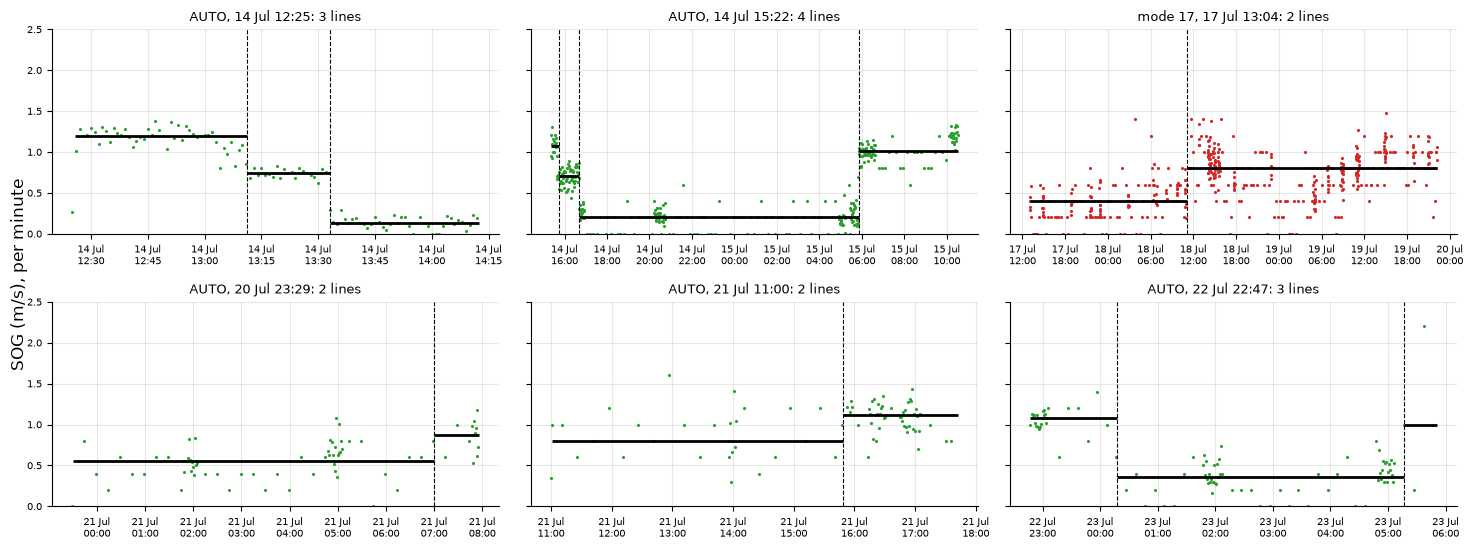

In [3]:
split = [k for k, g in m.groupby("mode_line") if g.line.nunique() > 1]
ncols = 3; nrows = int(np.ceil(len(split) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.8 * nrows), sharey=True)
for ax, k in zip(axes.ravel(), split):
    g = m[m.mode_line == k]
    pmin = g.dropna(subset=["groundspeed_ms"]).set_index("t").groundspeed_ms.resample("1min").mean().dropna()
    ax.plot(pmin.index, pmin.values, ".", ms=2.5, color=MODE_COLORS[int(g["mode"].iloc[0])])
    for ln in g.line.unique():
        r = lines.loc[ln]
        ax.hlines(r["SOG (m/s)"], r["from"], r["to"], color="k", lw=2)
        if r["new because"] == "speed":
            ax.axvline(r["from"], color="k", ls="--", lw=0.8)
    ax.set_title(f"{MODE_NAMES[int(g['mode'].iloc[0])]}, {g.t.min():%d %b %H:%M}: {g.line.nunique()} lines", fontsize=9)
    ax.set_ylim(0, 2.5); ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
for ax in axes.ravel()[len(split):]:
    ax.set_visible(False)
fig.supylabel("SOG (m/s), per minute")
plt.tight_layout(); plt.show()

### The timeline

Top row: mode. Bottom row: armed (dark) or disarmed (light). Each bar is one line of the mission. Short lines are drawn at least 3 min wide so they show; on the 17-day view many of them still merge, so the second plot zooms on 14 Jul, the busiest day.

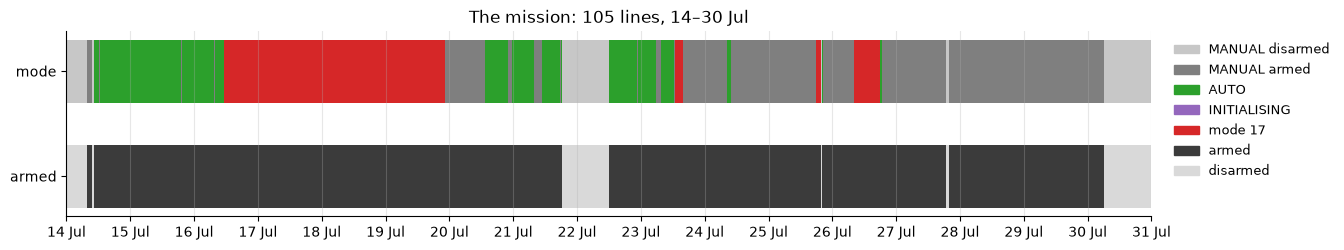

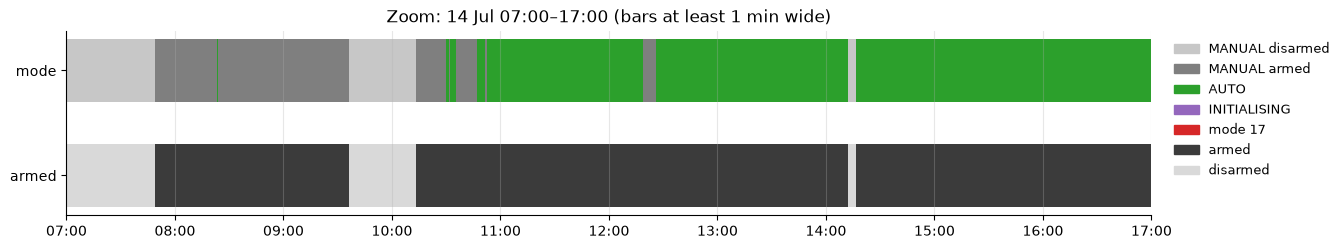

In [4]:
from matplotlib.patches import Patch

def timeline(ax, t0, t1, min_w="3min"):
    sel = lines[(lines["to"] > t0) & (lines["from"] < t1)]
    for r in sel.itertuples():
        w = max(r.to - r._1, pd.Timedelta(min_w))   # r._1 = "from"
        ax.barh(1, w, left=r._1, height=0.6, color=MODE_COLORS[r.mode_id], lw=0)
        ax.barh(0, w, left=r._1, height=0.6, color="#3b3b3b" if r.armed else "#d9d9d9", lw=0)
    ax.set_yticks([0, 1], ["armed", "mode"]); ax.set_xlim(t0, t1); ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=c, label=PLOT_NAMES[k]) for k, c in MODE_COLORS.items()]
                      + [Patch(color="#3b3b3b", label="armed"), Patch(color="#d9d9d9", label="disarmed")],
              loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)

fig, ax = plt.subplots(figsize=(14, 2.4))
timeline(ax, pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC"))
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title(f"The mission: {len(lines)} lines, 14–30 Jul")
plt.show()

fig, ax = plt.subplots(figsize=(14, 2.4))
timeline(ax, pd.Timestamp("2025-07-14 07:00", tz="UTC"), pd.Timestamp("2025-07-14 17:00", tz="UTC"), min_w="1min")
ax.xaxis.set_major_locator(mdates.HourLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("Zoom: 14 Jul 07:00–17:00 (bars at least 1 min wide)")
plt.show()

### Map: track coloured by mode

Every fix (both links), coloured by the mode it reported. Numbers = day of July at 00:00 UTC.

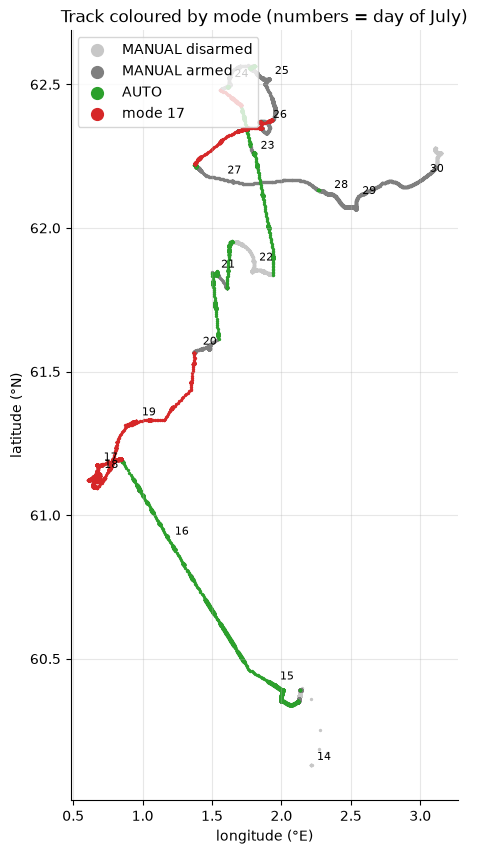

In [5]:
track = m[m.latitude_deg.between(55, 70)]
lat_mid = track.latitude_deg.median()
fig, ax = plt.subplots(figsize=(10, 10))
track_cat = np.where((track["mode"] == 0) & (track.armed == 0), -1, track["mode"])
for mode in [-1, 0, 10, 17]:
    p = track[track_cat == mode]
    ax.scatter(p.longitude_deg, p.latitude_deg, s=2, color=MODE_COLORS[mode], label=PLOT_NAMES[mode])
for day in pd.date_range("2025-07-14", "2025-07-30", tz="UTC"):
    p = track[track.t >= day].head(1)
    if len(p):
        ax.annotate(f"{day:%d}", (p.longitude_deg.iloc[0], p.latitude_deg.iloc[0]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_aspect(1 / np.cos(np.radians(lat_mid)))
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.legend(markerscale=6, loc="upper left"); ax.set_title("Track coloured by mode (numbers = day of July)")
plt.show()

# 2. Inside each leg

Each line of the mission is a **leg**: one mode, armed or not, from one change to the next. Here we look at what the boat did during each leg.

Everything is in **per-minute means** (so 1 Hz Starlink stretches don't outweigh Iridium):
- **SOG** = speed over ground (both links)
- **motor (W)** = load − 10 W hotel − 22 W × Starlink (both links), roughly the thruster
- **net speed** = straight-line distance from the leg's first fix to its last, divided by the leg's duration. Net speed ≈ SOG means a straight run; net speed ≪ SOG means circling or zig-zagging

Plots, in order:
1. Speed and motor power over the whole deployment, with the legs as coloured bands
2. One point per leg: SOG vs motor power, and net speed vs SOG
3. One panel per leg (legs ≥ 30 min): SOG over time
4. One panel per leg (legs ≥ 30 min): motor power vs SOG, with the correlation r
5. Correlation by mode, over all minutes
6. MANUAL legs on a map: where the boat drifted, and how fast

In [6]:
# per-minute means inside each leg
m["minute"] = m.t.dt.floor("1min")
pm = (m.groupby(["line", "minute"])
        .agg(SOG=("groundspeed_ms", "mean"), motor=("P_motor", "mean"), starlink=("starlink", "mean"),
             lat=("latitude_deg", "mean"), lon=("longitude_deg", "mean"))
        .reset_index())
pm = pm.merge(lines[["mode_id", "armed", "from"]], left_on="line", right_index=True)
pm["h_in_leg"] = (pm.minute - pm["from"]).dt.total_seconds() / 3600

# net speed per leg: first to last real fix
def net_speed(g):
    f = g[g.latitude_deg.between(55, 70)]
    if len(f) < 2:
        return np.nan
    dt = (f.t.iloc[-1] - f.t.iloc[0]).total_seconds()
    return dist_m(f.latitude_deg.iloc[0], f.longitude_deg.iloc[0], f.latitude_deg.iloc[-1], f.longitude_deg.iloc[-1]) / dt if dt > 0 else np.nan

def bearing(g):
    f = g[g.latitude_deg.between(55, 70)]
    if len(f) < 2:
        return np.nan
    la1, lo1, la2, lo2 = np.radians([f.latitude_deg.iloc[0], f.longitude_deg.iloc[0], f.latitude_deg.iloc[-1], f.longitude_deg.iloc[-1]])
    return np.degrees(np.arctan2(np.sin(lo2 - lo1) * np.cos(la2), np.cos(la1) * np.sin(la2) - np.sin(la1) * np.cos(la2) * np.cos(lo2 - lo1))) % 360

lines["net speed (m/s)"] = m.groupby("line").apply(net_speed).values
lines["net direction (°)"] = m.groupby("line").apply(bearing).values
lines["straightness"] = lines["net speed (m/s)"] / lines["SOG (m/s)"]
LONG = lines[lines.hours >= 0.5]
print(f"{len(pm)} leg-minutes; {len(LONG)} legs of 30 min or more: " + ", ".join(f"{k} {v}" for k, v in LONG["mode"].value_counts().items()))

5961 leg-minutes; 47 legs of 30 min or more: AUTO 23, MANUAL 16, mode 17 8


## 2.1 Speed and motor power over the whole deployment

Top: per-minute SOG. Bottom: per-minute motor power. Two separate panels, same time axis. The background band shows the mode of each leg. SOG is cropped at 3 m/s and motor at −20…200 W (a few points fall outside).

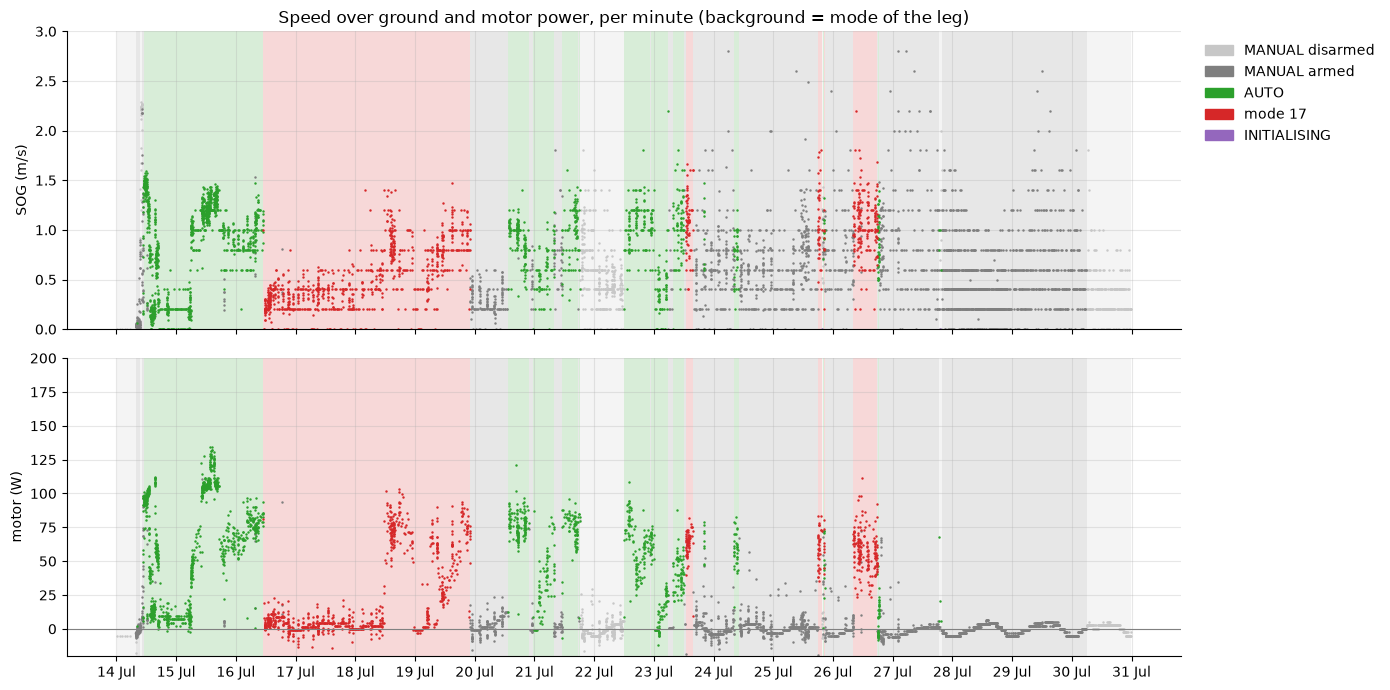

In [7]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax in (a1, a2):
    for _, r in lines.iterrows():
        ax.axvspan(r["from"], r["to"], color=MODE_COLORS[r.mode_id], alpha=0.18, lw=0)
for mode in [-1, 0, 10, 17, 16]:
    g = pm[pm.mode_id == mode]
    a1.plot(g.minute, g.SOG, ".", ms=1.5, color=MODE_COLORS[mode])
    a2.plot(g.minute, g.motor, ".", ms=1.5, color=MODE_COLORS[mode])
a1.set_ylim(0, 3); a1.set_ylabel("SOG (m/s)")
a2.set_ylim(-20, 200); a2.set_ylabel("motor (W)"); a2.axhline(0, color="grey", lw=0.8)
a1.legend(handles=[Patch(color=MODE_COLORS[k], label=PLOT_NAMES[k]) for k in [-1, 0, 10, 17, 16]], loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
a2.xaxis.set_major_locator(mdates.DayLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
a1.set_title("Speed over ground and motor power, per minute (background = mode of the leg)")
plt.tight_layout(); plt.show()

## 2.2 One point per leg

Each dot is a leg: its median per-minute values. Dot size = leg duration. Left: SOG vs motor power. Right: net speed vs SOG; the dashed line is net = SOG (a perfectly straight leg). Legs under 5 min have too few minutes to say much: they're drawn hollow.

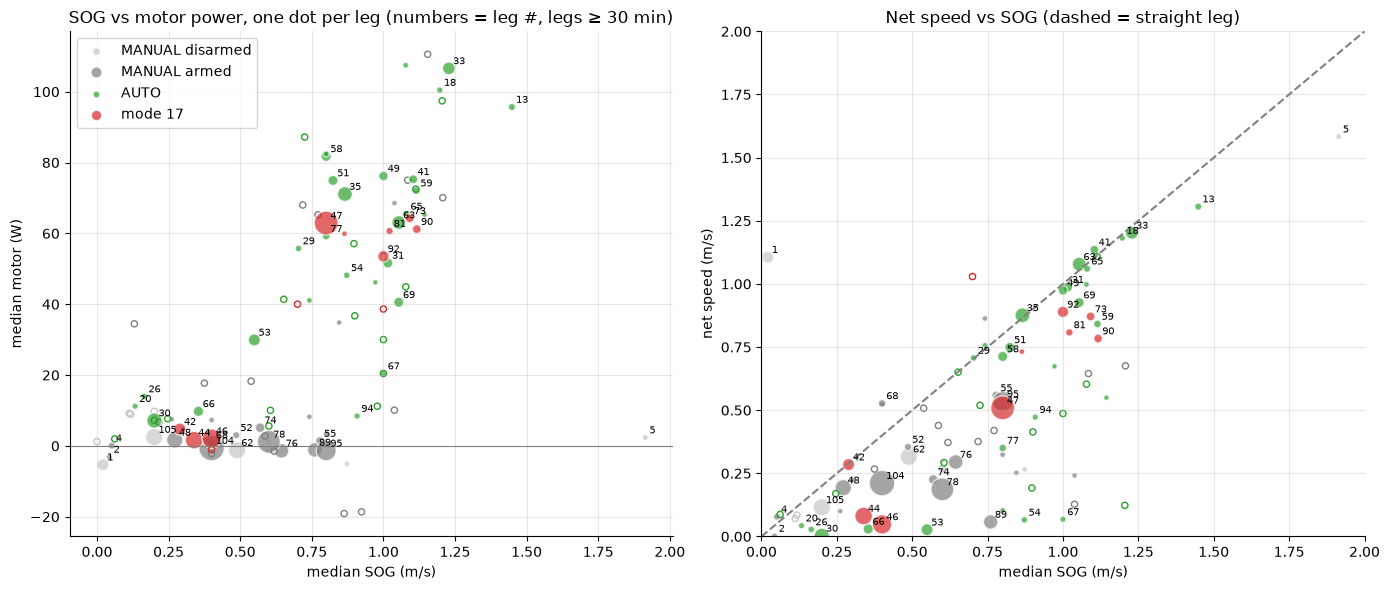

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
for mode in [-1, 0, 10, 17]:
    g = lines[lines.mode_id == mode]
    big, small = g[g.hours >= 1 / 12], g[g.hours < 1 / 12]
    sz = 15 + 8 * big.hours.clip(upper=40)
    a1.scatter(big["SOG (m/s)"], big["motor (W)"], s=sz, color=MODE_COLORS[mode], alpha=0.7, edgecolor="white", label=PLOT_NAMES[mode])
    a1.scatter(small["SOG (m/s)"], small["motor (W)"], s=20, facecolor="none", edgecolor=MODE_COLORS[mode])
    a2.scatter(big["SOG (m/s)"], big["net speed (m/s)"], s=sz, color=MODE_COLORS[mode], alpha=0.7, edgecolor="white", label=PLOT_NAMES[mode])
    a2.scatter(small["SOG (m/s)"], small["net speed (m/s)"], s=20, facecolor="none", edgecolor=MODE_COLORS[mode])
for k, r in LONG.iterrows():
    a1.annotate(str(k), (r["SOG (m/s)"], r["motor (W)"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    a2.annotate(str(k), (r["SOG (m/s)"], r["net speed (m/s)"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
a1.axhline(0, color="grey", lw=0.8)
a1.set_xlabel("median SOG (m/s)"); a1.set_ylabel("median motor (W)"); a1.set_title("SOG vs motor power, one dot per leg (numbers = leg #, legs ≥ 30 min)")
a2.plot([0, 2], [0, 2], "--", color="grey"); a2.set_xlim(0, 2); a2.set_ylim(0, 2)
a2.set_xlabel("median SOG (m/s)"); a2.set_ylabel("net speed (m/s)"); a2.set_title("Net speed vs SOG (dashed = straight leg)")
a1.legend(loc="upper left", markerscale=0.6)
plt.tight_layout(); plt.show()

## 2.3 Speed over time, one panel per leg (legs ≥ 30 min)

x = hours since the leg started (each panel has its own length), y = per-minute SOG, cropped at 2.5 m/s. Colour = mode. The title has the leg number, mode, start time and length.

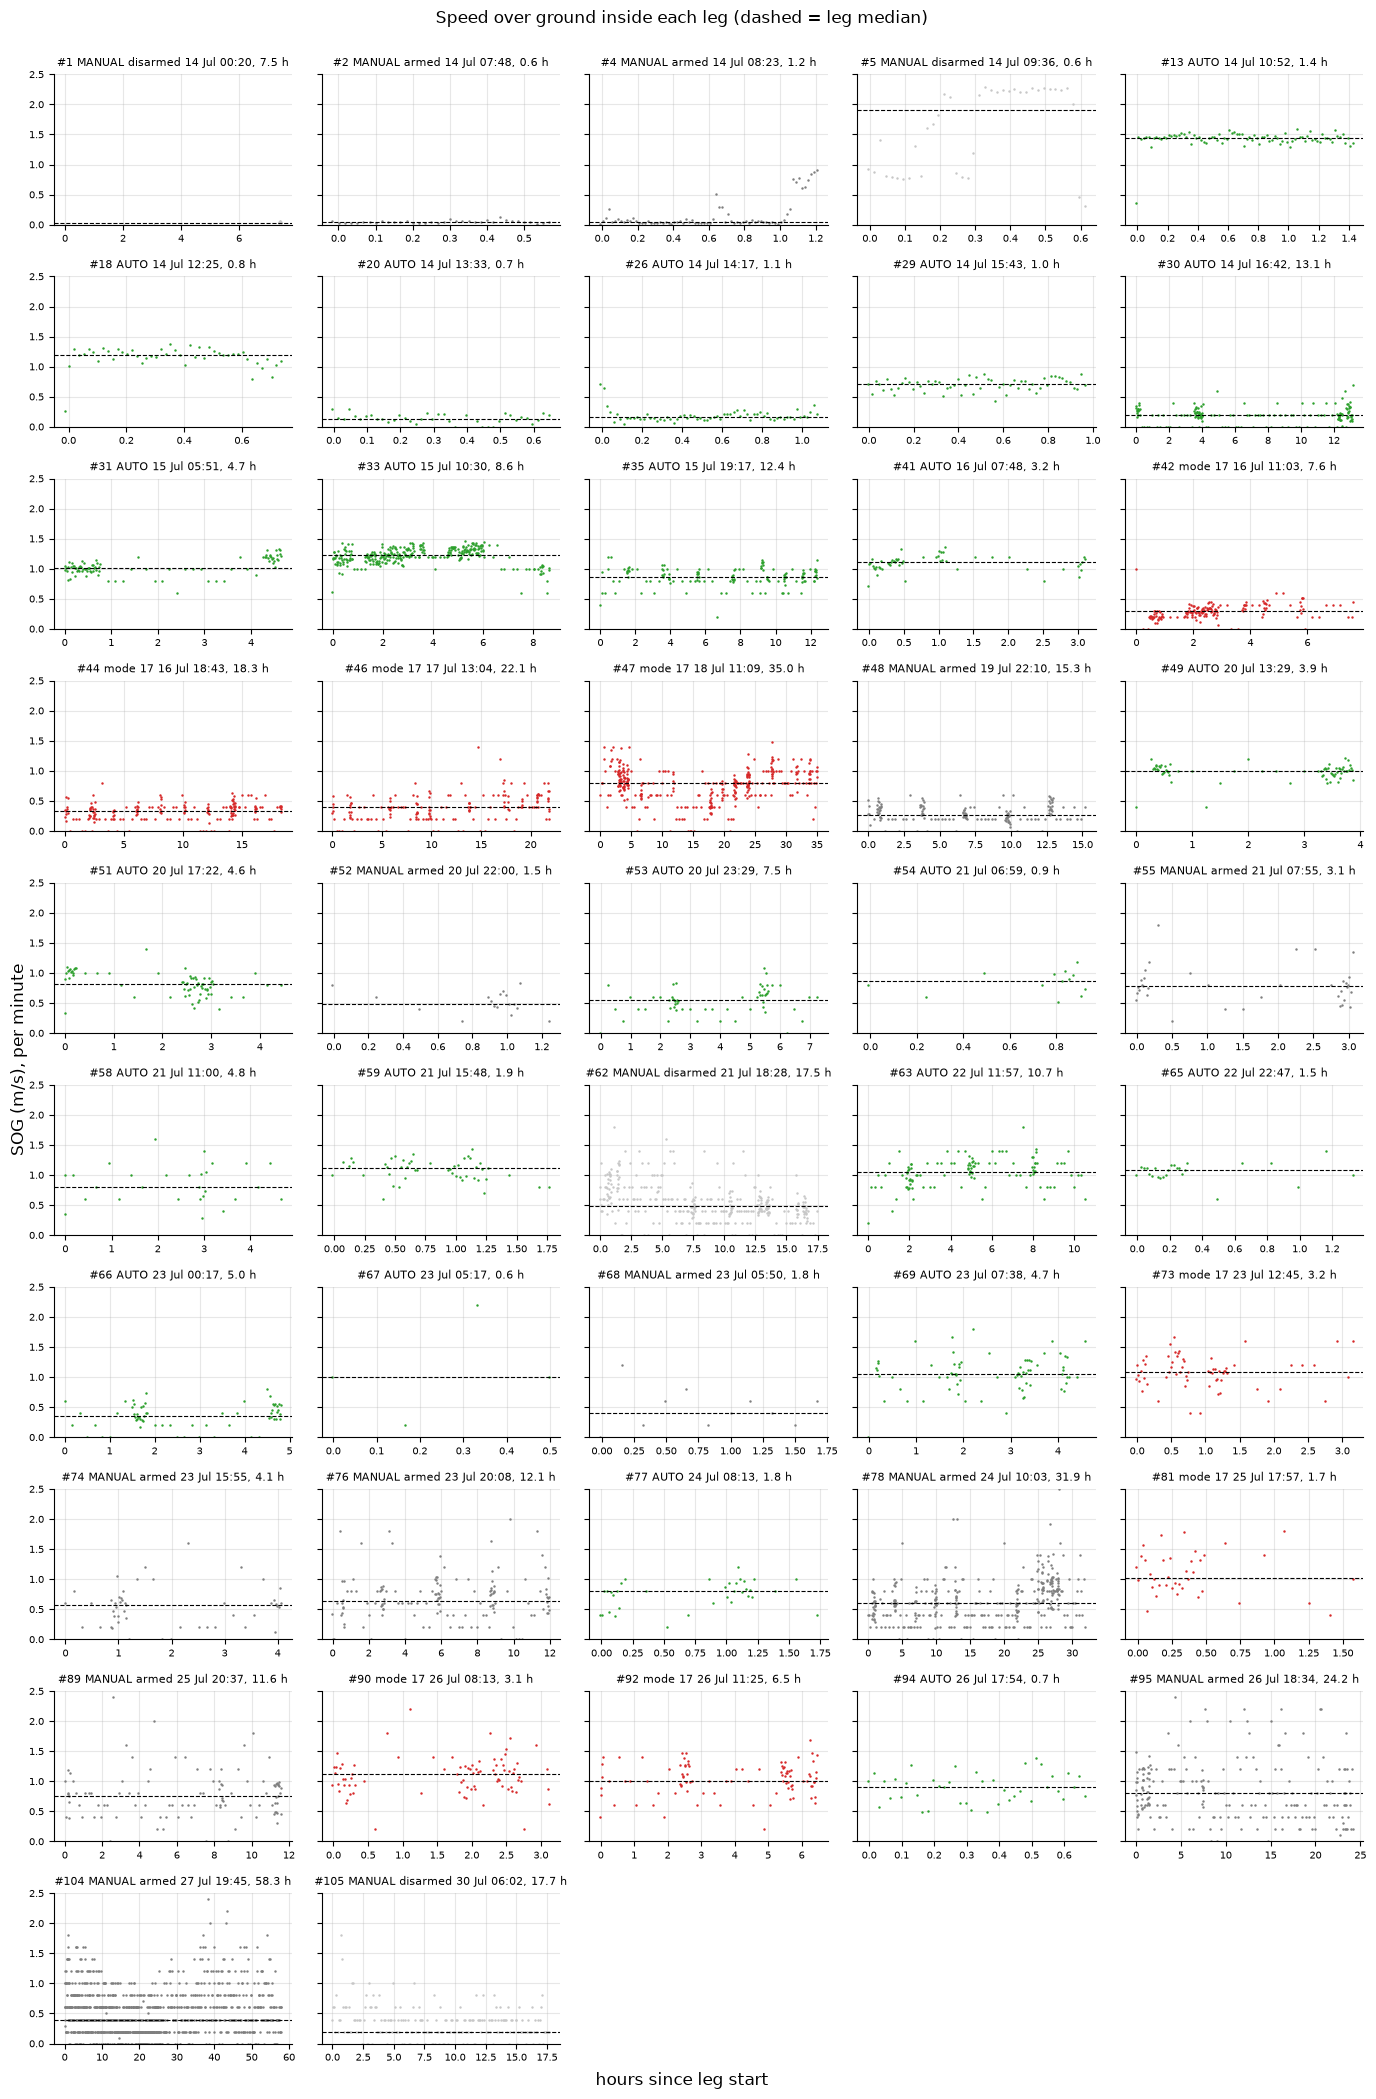

In [9]:
def leg_grid(plot_one, ncols=5, sharex=False, sharey=True, height=2.1):
    n = len(LONG); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, height * nrows), sharex=sharex, sharey=sharey)
    axes = axes.ravel()
    for ax, (k, r) in zip(axes, LONG.iterrows()):
        plot_one(ax, k, r, pm[pm.line == k])
        ax.tick_params(labelsize=7)
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

def sog_one(ax, k, r, g):
    ax.plot(g.h_in_leg, g.SOG, ".", ms=1.5, color=MODE_COLORS[r.mode_id])
    ax.axhline(r["SOG (m/s)"], color="k", lw=0.8, ls="--")
    ax.set_ylim(0, 2.5)
    ax.set_title(f"#{k} {PLOT_NAMES[r.mode_id]} {r['from']:%d %b %H:%M}, {r.hours:.1f} h", fontsize=8)

fig, axes = leg_grid(sog_one)
fig.supxlabel("hours since leg start"); fig.supylabel("SOG (m/s), per minute")
fig.suptitle("Speed over ground inside each leg (dashed = leg median)", y=1.0)
plt.tight_layout(); plt.show()

## 2.4 Motor power vs SOG, one panel per leg (legs ≥ 30 min)

Each dot is a minute of the leg. **r** = Pearson correlation between per-minute SOG and motor power inside that leg (blank if fewer than 10 minutes with both). Axes shared: SOG 0–2.5 m/s, motor −20…200 W.

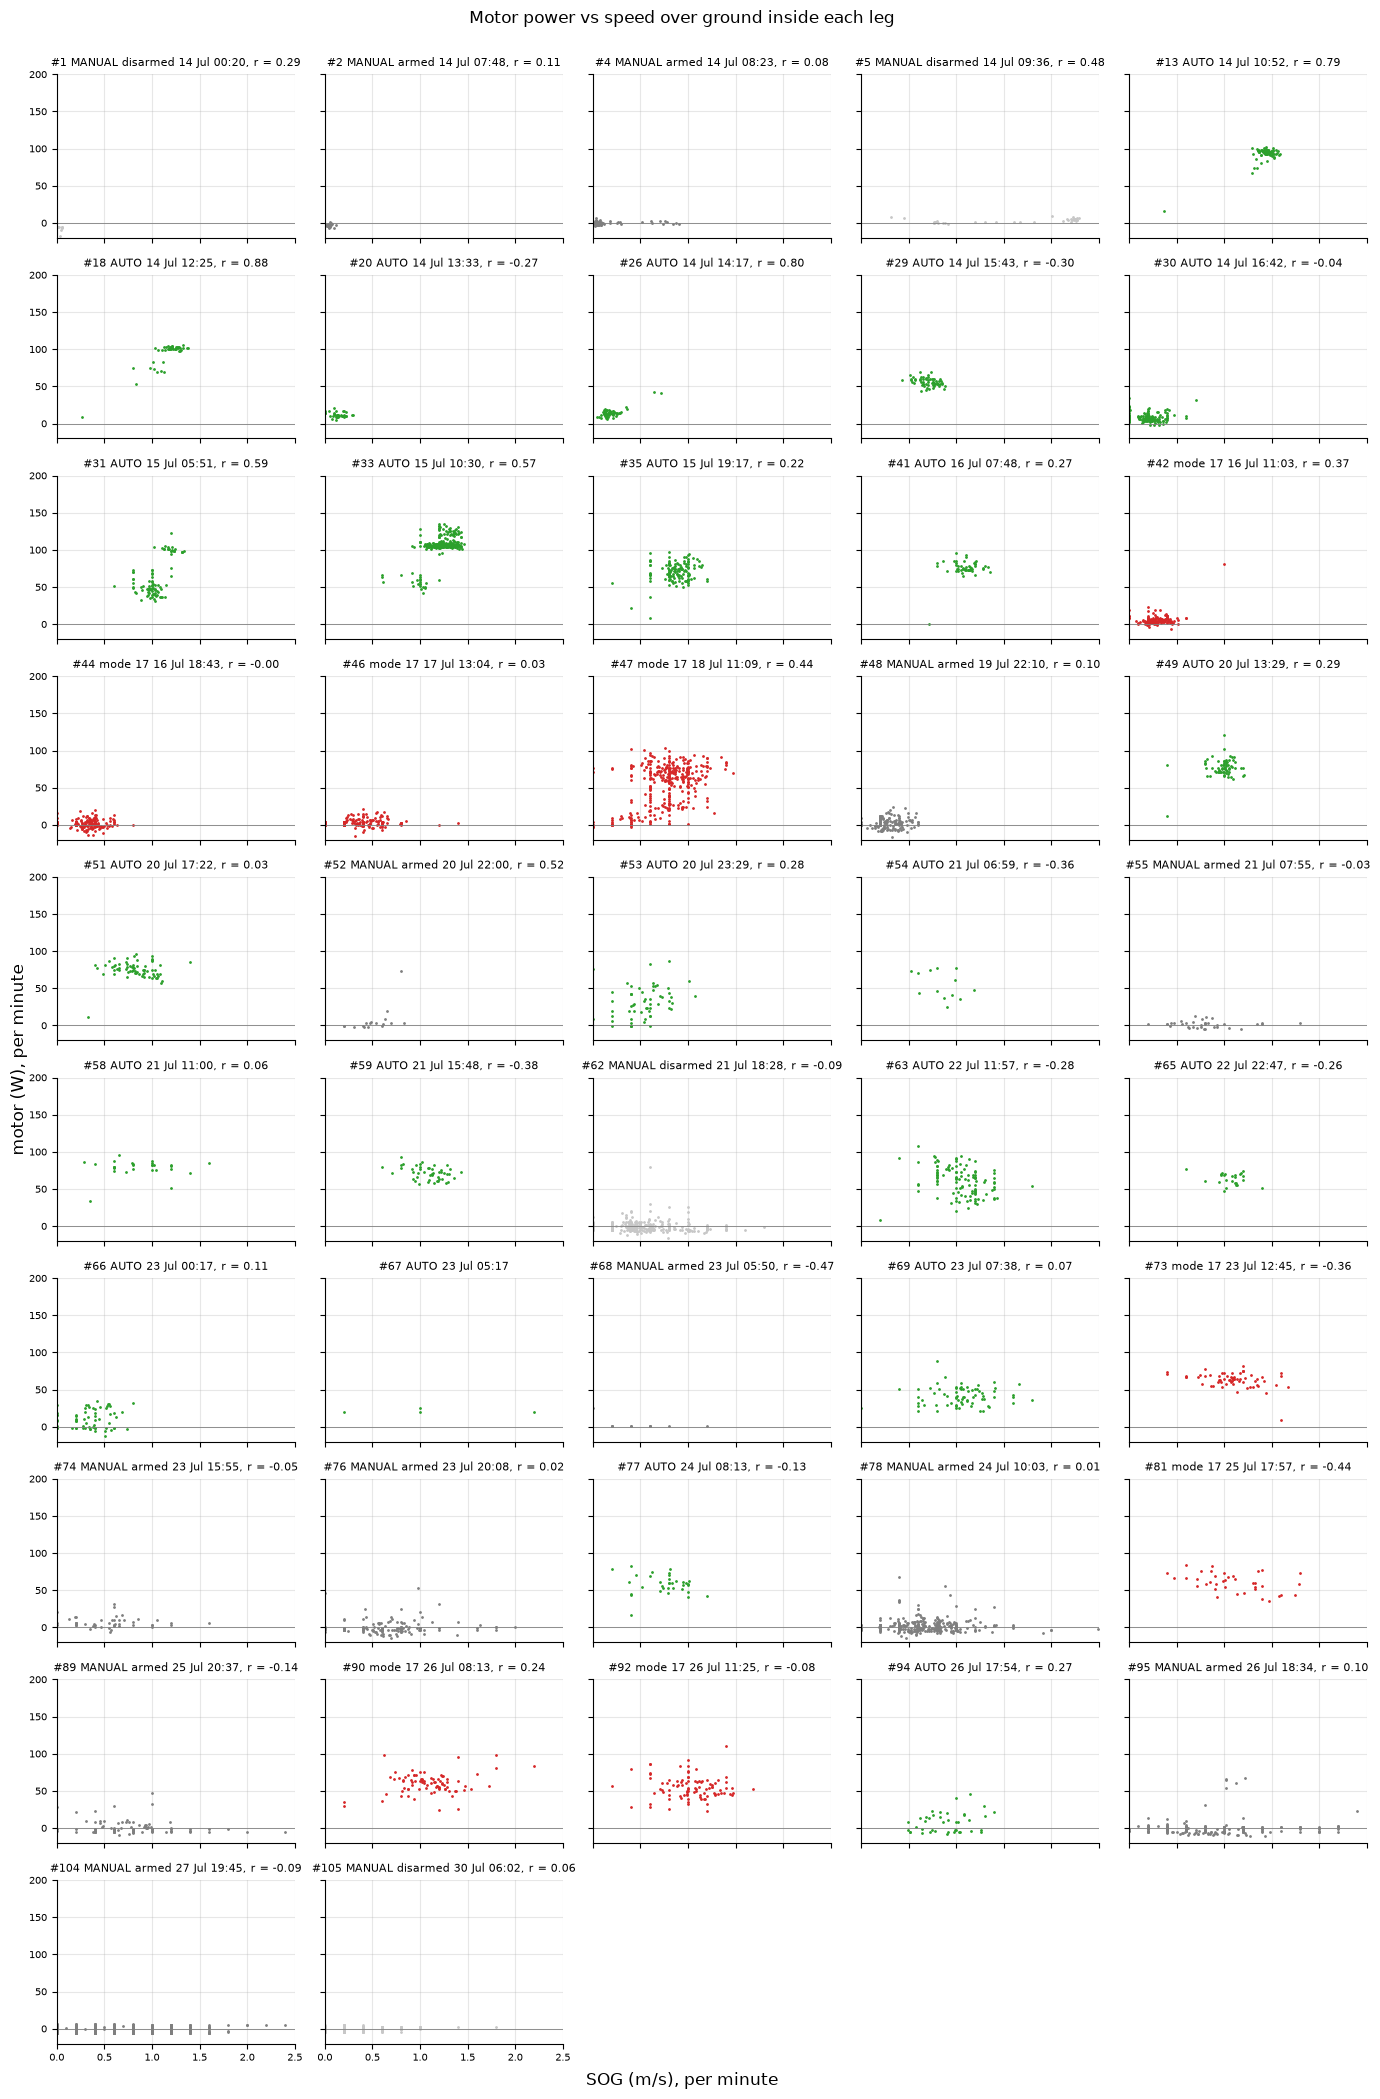

In [10]:
def r_in(g):
    x = g.dropna(subset=["SOG", "motor"])
    return x.SOG.corr(x.motor) if len(x) >= 10 else np.nan

lines["r SOG–motor"] = [r_in(pm[pm.line == k]) for k in lines.index]
LONG = lines[lines.hours >= 0.5]

def corr_one(ax, k, r, g):
    ax.plot(g.SOG, g.motor, ".", ms=2, color=MODE_COLORS[r.mode_id])
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xlim(0, 2.5); ax.set_ylim(-20, 200)
    rr = r["r SOG–motor"]
    ax.set_title(f"#{k} {PLOT_NAMES[r.mode_id]} {r['from']:%d %b %H:%M}" + (f", r = {rr:.2f}" if pd.notna(rr) else ""), fontsize=8)

fig, axes = leg_grid(corr_one, sharex=True)
fig.supxlabel("SOG (m/s), per minute"); fig.supylabel("motor (W), per minute")
fig.suptitle("Motor power vs speed over ground inside each leg", y=1.0)
plt.tight_layout(); plt.show()

## 2.5 Correlation by mode, over all minutes

All leg-minutes pooled by mode (and armed). Pearson r between SOG, motor power and Starlink share in that minute. Plus the per-leg table: the long legs with their medians, net speed, straightness (net / SOG) and r.

In [11]:
rows = []
for (mode, armed), g in pm.groupby(["mode_id", "armed"]):
    x = g.dropna(subset=["SOG", "motor"])
    rows.append({"mode": MODE_NAMES.get(mode, "MANUAL"), "armed": bool(armed), "minutes": len(x),
                 "median SOG (m/s)": x.SOG.median(), "median motor (W)": x.motor.median(),
                 "r SOG–motor": x.SOG.corr(x.motor) if len(x) >= 10 else np.nan,
                 "r SOG–Starlink": x.SOG.corr(x.starlink) if len(x) >= 10 else np.nan})
pd.DataFrame(rows).set_index(["mode", "armed"]).round(2)

minutes  median SOG (m/s)  median motor (W)  r SOG–motor  \
mode         armed                                                             
MANUAL       False      637              0.40             -0.01         0.01   
             True      2425              0.48             -0.22         0.10   
AUTO         False        1              0.98             11.20          NaN   
             True      1767              0.98             65.86         0.76   
INITIALISING False        0               NaN               NaN          NaN   
mode 17      False        1              0.40             -0.98          NaN   
             True      1125              0.60             22.27         0.70   

                    r SOG–Starlink  
mode         armed                  
MANUAL       False            0.24  
             True             0.04  
AUTO         False             NaN  
             True             0.23  
INITIALISING False             NaN  
mode 17      False             NaN  
             True             0.15

In [12]:
(LONG[["from", "hours", "mode", "armed", "SOG (m/s)", "net speed (m/s)", "straightness", "net direction (°)", "motor (W)", "r SOG–motor"]]
    .style.format({"from": "{:%d %b %H:%M}", "hours": "{:.1f}", "SOG (m/s)": "{:.2f}", "net speed (m/s)": "{:.2f}",
                   "straightness": "{:.2f}", "net direction (°)": "{:.0f}", "motor (W)": "{:.0f}", "r SOG–motor": "{:.2f}"}, na_rep="")
    .apply(lambda col: [f"background-color: {MODE_COLORS[k]}33" for k in LONG.mode_id], subset=["mode"]))

,from,hours,mode,armed,SOG (m/s),net speed (m/s),straightness,net direction (°),motor (W),r SOG–motor
#,,,,,,,,,,
1,14 Jul 00:20,7.5,MANUAL,False,0.02,1.11,53.20,351,-5,0.29
2,14 Jul 07:48,0.6,MANUAL,True,0.04,0.00,0.05,211,-3,0.11
4,14 Jul 08:23,1.2,MANUAL,True,0.05,0.08,1.53,149,0,0.08
5,14 Jul 09:36,0.6,MANUAL,False,1.91,1.58,0.83,193,2,0.48
13,14 Jul 10:52,1.4,AUTO,True,1.45,1.31,0.90,273,96,0.79
18,14 Jul 12:25,0.8,AUTO,True,1.20,1.18,0.99,6,100,0.88
20,14 Jul 13:33,0.7,AUTO,True,0.13,0.04,0.32,116,11,-0.27
26,14 Jul 14:17,1.1,AUTO,True,0.17,0.03,0.17,232,14,0.80
29,14 Jul 15:43,1.0,AUTO,True,0.70,0.71,1.00,304,56,-0.30


## 2.6 MANUAL legs: where the boat drifted

Motor off, so the boat moves with wind and current only. Each arrow goes from the leg's first fix to its last; colour = net drift speed. Only MANUAL legs ≥ 30 min. The whole track is in light grey behind.

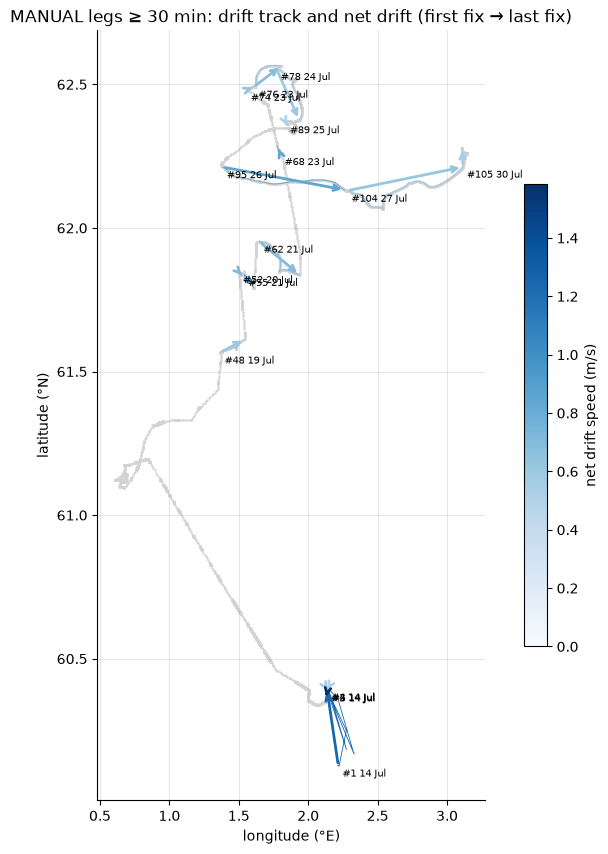

/tmp/ipykernel_88709/3143384887.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  man[["from", "hours", "net speed (m/s)", "net direction (°)", "SOG (m/s)"]].round(2)


,from,hours,net speed (m/s),net direction (°),SOG (m/s)
#,,,,,
1,2025-07-14 00:20:51.060558+00:00,7.47,1.11,351.45,0.02
2,2025-07-14 07:48:57.927821+00:00,0.57,0.00,210.82,0.04
4,2025-07-14 08:23:35.769307+00:00,1.21,0.08,149.26,0.05
5,2025-07-14 09:36:16.885741+00:00,0.62,1.58,192.56,1.91
48,2025-07-19 22:10:29.975030+00:00,15.31,0.19,60.92,0.27
52,2025-07-20 22:00:29.223335+00:00,1.49,0.35,137.16,0.49
55,2025-07-21 07:55:39.464905+00:00,3.07,0.56,143.95,0.78
62,2025-07-21 18:28:00.349391+00:00,17.48,0.32,130.12,0.49
68,2025-07-23 05:50:44.883539+00:00,1.80,0.53,338.55,0.40


In [13]:
man = LONG[LONG.mode_id.isin([-1, 0])]   # MANUAL, armed or disarmed
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(track.longitude_deg, track.latitude_deg, s=0.5, color="lightgrey", zorder=0)
norm = plt.Normalize(0, max(0.6, man["net speed (m/s)"].max()))
cmap = plt.cm.Blues
for k, r in man.iterrows():
    f = m[(m.line == k) & m.latitude_deg.between(55, 70)]
    x0, y0, x1, y1 = f.longitude_deg.iloc[0], f.latitude_deg.iloc[0], f.longitude_deg.iloc[-1], f.latitude_deg.iloc[-1]
    c = cmap(0.3 + 0.7 * norm(r["net speed (m/s)"]))
    ax.plot(f.longitude_deg, f.latitude_deg, "-", lw=0.6, color=c, zorder=1)
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=c, lw=2), zorder=2)
    ax.annotate(f"#{k} {r['from']:%d %b}", (x0, y0), fontsize=7, xytext=(3, -8), textcoords="offset points")
sm_ = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm_, ax=ax, shrink=0.6, label="net drift speed (m/s)")
ax.set_aspect(1 / np.cos(np.radians(lat_mid)))
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title("MANUAL legs ≥ 30 min: drift track and net drift (first fix → last fix)")
plt.show()
man[["from", "hours", "net speed (m/s)", "net direction (°)", "SOG (m/s)"]].round(2)

# 3. The mission

The full list of commands, from the first message (14 Jul 00:20) to the last (30 Jul 23:42). Read each line as: *from `from` to `to`, the boat is in `mode`, armed or not.*

| column | what it is |
| --- | --- |
| **from / to** | when the line starts (first message in the new state) and ends (start of the next line) |
| **mode / armed** | the command: what the operator set |
| **new because** | what started the line: a change of mode/arming, or a speed step |
| **seen within (min)** | gap to the previous message: the switch happened up to this many minutes before `from` |
| **via** | which links reported during the line |
| **lat / lon** | where the boat was at the start |
| **wp lat / wp lon** | the active waypoint (last one reported, Starlink only; blank if Starlink didn't report one) |
| **SOG (m/s)** | **what happened, not a command:** median of per-minute means of speed over ground. For checking only |

Plus the Starlink schedule from nb 05 (`data/mission/mission_starlink.csv`), which runs alongside the modes.

Saved to `data/mission/mission_modes.csv`. The old 1 m/s waypoint file `data/mission/mission_waypoints.csv` is no longer written by this notebook; nb 12 still reads it until the forecast moves to this mission.

In [14]:
pd.set_option("display.max_rows", 200)
MISSION = lines[["from", "to", "hours", "mode", "armed", "new because", "seen within (min)", "via", "lat", "lon", "wp lat", "wp lon", "SOG (m/s)"]]
(MISSION.style
    .format({"from": "{:%d %b %H:%M:%S}", "to": "{:%d %b %H:%M:%S}", "hours": "{:.2f}", "seen within (min)": "{:.1f}",
             "lat": "{:.3f}", "lon": "{:.3f}", "wp lat": "{:.3f}", "wp lon": "{:.3f}", "SOG (m/s)": "{:.2f}"}, na_rep="")
    .apply(lambda col: [f"background-color: {MODE_COLORS[k]}33" for k in lines.mode_id], subset=["mode"]))

,from,to,hours,mode,armed,new because,seen within (min),via,lat,lon,wp lat,wp lon,SOG (m/s)
#,,,,,,,,,,,,,
1,14 Jul 00:20:51,14 Jul 07:48:57,7.47,MANUAL,False,mode/arming,,Iridium+Starlink,60.128,2.216,60.128,2.196,0.02
2,14 Jul 07:48:57,14 Jul 08:23:16,0.57,MANUAL,True,mode/arming,0.2,Starlink,60.393,2.136,60.128,2.196,0.04
3,14 Jul 08:23:16,14 Jul 08:23:35,0.01,AUTO,True,mode/arming,0.0,Starlink,60.392,2.136,60.128,2.196,0.06
4,14 Jul 08:23:35,14 Jul 09:36:16,1.21,MANUAL,True,mode/arming,0.3,Iridium+Starlink,60.392,2.136,60.128,2.196,0.05
5,14 Jul 09:36:16,14 Jul 10:13:17,0.62,MANUAL,False,mode/arming,0.0,Iridium+Starlink,60.390,2.139,60.128,2.196,1.91
6,14 Jul 10:13:17,14 Jul 10:29:55,0.28,MANUAL,True,mode/arming,0.0,Starlink,60.359,2.125,60.128,2.196,0.74
7,14 Jul 10:29:55,14 Jul 10:31:30,0.03,AUTO,True,mode/arming,0.0,Starlink,60.352,2.119,60.351,2.119,0.72
8,14 Jul 10:31:30,14 Jul 10:32:15,0.01,MANUAL,True,mode/arming,0.3,Starlink,60.351,2.119,60.351,2.119,0.59
9,14 Jul 10:32:15,14 Jul 10:35:15,0.05,AUTO,True,mode/arming,0.3,Starlink,60.351,2.118,60.351,2.119,1.21


In [15]:
out = MISSION.round({"hours": 3, "seen within (min)": 2, "lat": 5, "lon": 5, "wp lat": 5, "wp lon": 5, "SOG (m/s)": 2})
out.to_csv("../data/mission/mission_modes.csv", date_format="%Y-%m-%dT%H:%M:%SZ")
print(f"{len(MISSION)} mission lines saved to data/mission/mission_modes.csv")

105 mission lines saved to data/mission/mission_modes.csv
